# Parkinson's Speech Dataset Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!pip show scikit-learn

Name: scikit-learn
Version: 1.1.3
Summary: A set of python modules for machine learning and data mining
Home-page: http://scikit-learn.org
Author: 
Author-email: 
License: new BSD
Location: /Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages
Requires: joblib, numpy, scipy, threadpoolctl
Required-by: 


In [3]:
from sklearn import svm
from sklearn.model_selection import train_test_split, GridSearchCV

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('max_colwidth', None)

In [5]:
df = pd.read_csv ('train_data.txt', delimiter=",", header=0, index_col = [0], 
                        names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks',
                               'UPDRS', 
                               'class_information']) 

df.head()

,Jitter_local,Jitter_local_absolute,Jitter_rap,Jitter_ppq5,Jitter_ddp,Shimmer_local,Shimmer_local_dB,Shimmer_apq3,Shimmer_apq5,Shimmer_apq11,Shimmer_dda,AC,NTH,HTN,Median_pitch,Mean_pitch,Standard_deviation,Minimum_pitch,Maximum_pitch,Number_of_pulses,Number_of_periods,Mean_period,Standard_deviation_of_period,Fraction_of_locally_unvoiced_frames,Number_of_voice_breaks,Degree_of_voice_breaks,UPDRS,class_information
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,0.728,0.000038,0.353,0.376,1.059,5.864,0.642,2.058,3.180,7.194,6.175,0.951285,0.066758,17.403,195.252,193.289,14.773,159.515,234.505,170.0,169.0,0.005181,0.000403,2.247,0.0,0.000,23,1.0
1,1.220,0.000074,0.732,0.670,2.196,8.719,0.875,4.347,5.166,7.548,13.040,0.911508,0.109983,12.212,158.689,164.768,12.981,146.445,211.442,1431.0,1427.0,0.006071,0.000474,10.656,1.0,0.178,23,1.0
1,2.502,0.000123,1.156,1.634,3.469,13.513,1.273,5.263,8.771,16.779,15.789,0.901302,0.121982,11.384,201.997,203.471,10.853,182.713,220.230,94.0,92.0,0.004910,0.000320,0.000,0.0,0.000,23,1.0
1,3.509,0.000167,1.715,1.539,5.145,9.112,1.040,3.102,4.927,12.823,9.307,0.856907,0.236831,10.653,211.887,208.440,11.499,182.821,225.162,117.0,114.0,0.004757,0.000380,18.182,1.0,13.318,23,1.0
1,2.470,0.000126,1.358,1.341,4.075,10.696,1.256,5.262,7.076,9.199,15.787,0.897708,0.152955,11.987,195.952,195.222,4.692,186.593,202.812,74.0,73.0,0.005118,0.000187,23.214,0.0,0.000,23,1.0


In [19]:
df.head().T

id,1,1,1,1,1
Jitter_local,0.728000,1.220000,2.502000,3.509000,2.470000
Jitter_local_absolute,0.000038,0.000074,0.000123,0.000167,0.000126
Jitter_rap,0.353000,0.732000,1.156000,1.715000,1.358000
Jitter_ppq5,0.376000,0.670000,1.634000,1.539000,1.341000
Jitter_ddp,1.059000,2.196000,3.469000,5.145000,4.075000
Shimmer_local,5.864000,8.719000,13.513000,9.112000,10.696000
Shimmer_local_dB,0.642000,0.875000,1.273000,1.040000,1.256000
Shimmer_apq3,2.058000,4.347000,5.263000,3.102000,5.262000
Shimmer_apq5,3.180000,5.166000,8.771000,4.927000,7.076000
Shimmer_apq11,7.194000,7.548000,16.779000,12.823000,9.199000


In [20]:
df.shape

(1043, 28)

## Data Visualization

<AxesSubplot:title={'center':'Distribution of UPDRS scores'}>

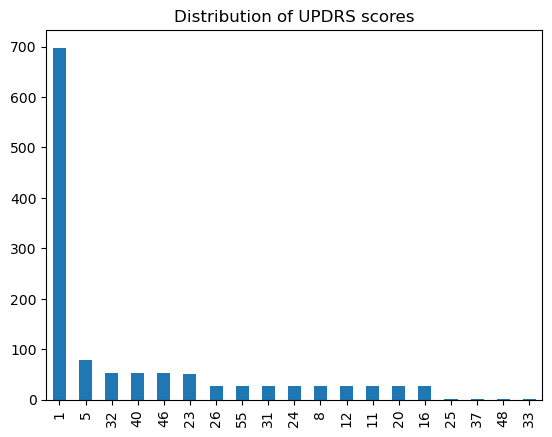

In [6]:
title = "Distribution of UPDRS scores"
to_plot = df.UPDRS.value_counts(dropna=False)
to_plot.plot.bar(title=title)

<AxesSubplot:title={'center':'Distribution of mean pitch'}, xlabel='Mean_pitch', ylabel='UPDRS'>

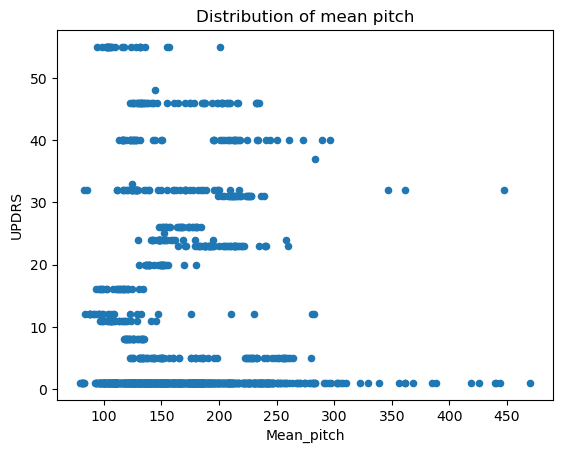

In [10]:
title = "Distribution of mean pitch"
df.plot.scatter("Mean_pitch", "UPDRS",title=title)

<AxesSubplot:title={'center':'Impact of the number of breaks on the UPDRS score'}, xlabel='Number_of_voice_breaks', ylabel='UPDRS'>

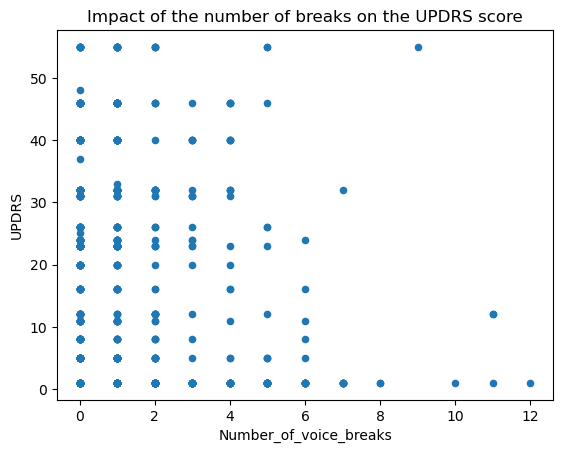

In [7]:
title = "Impact of the number of breaks on the UPDRS score"
df.plot.scatter("Number_of_voice_breaks", "UPDRS",title=title)

<AxesSubplot:title={'center':'Impact of the number of unspoken words on the UPDRS score'}, xlabel='Fraction_of_locally_unvoiced_frames', ylabel='UPDRS'>

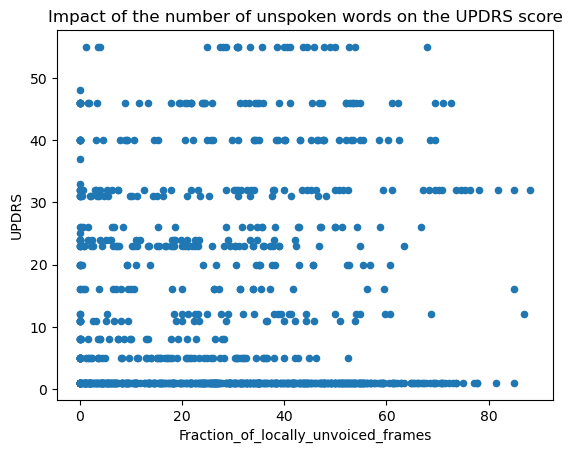

In [8]:
title = "Impact of the number of unspoken words on the UPDRS score"
df.plot.scatter("Fraction_of_locally_unvoiced_frames", "UPDRS",title=title)

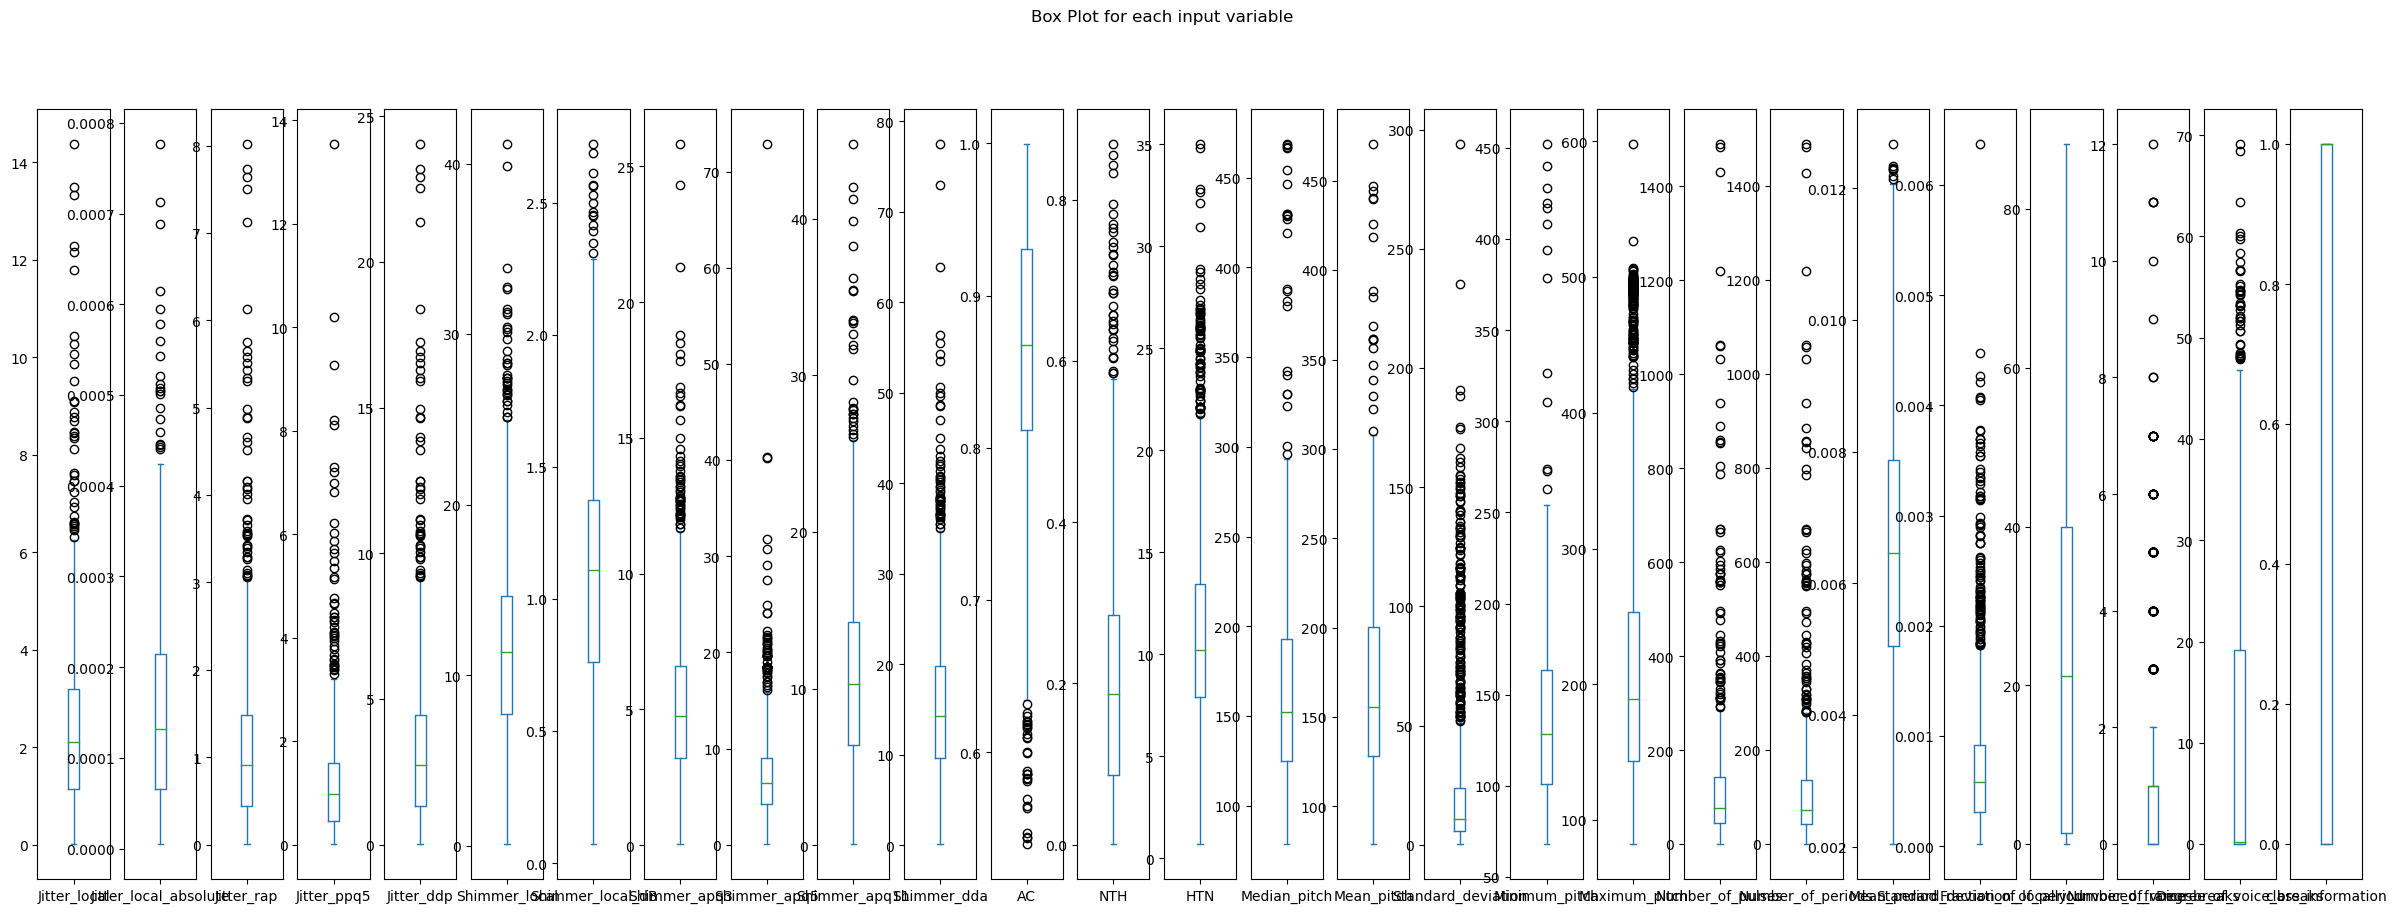

In [9]:
# BOX Plot

df.drop('UPDRS', axis=1).plot(kind='box', subplots=True, sharex=False, sharey=False, figsize=(30,10), 
                                        title='Box Plot for each input variable')

plt.show()

## Data Preparation

In [12]:
df_test = pd.read_csv ('test_data.txt', delimiter=",", header=0, index_col = [0], 
                        names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks', 
                               'class_information']) 
df_test.head().T

id,1,1,1,1,1
Jitter_local,0.143000,0.162000,0.140000,0.150000,0.208000
Jitter_local_absolute,0.000007,0.000008,0.000007,0.000007,0.000009
Jitter_rap,0.073000,0.087000,0.075000,0.080000,0.077000
Jitter_ppq5,0.081000,0.089000,0.089000,0.097000,0.095000
Jitter_ddp,0.219000,0.260000,0.224000,0.240000,0.230000
Shimmer_local,1.236000,1.338000,1.086000,1.049000,1.241000
Shimmer_local_dB,0.107000,0.117000,0.094000,0.091000,0.109000
Shimmer_apq3,0.612000,0.630000,0.556000,0.533000,0.487000
Shimmer_apq5,0.904000,0.948000,0.747000,0.698000,0.715000
Shimmer_apq11,0.894000,1.017000,0.823000,0.777000,1.568000


In [12]:
df_real_test = pd.read_csv ('actual_test_data.txt', delimiter=",", header=0, index_col = [0], 
                        names=['id',
                               'Jitter_local','Jitter_local_absolute','Jitter_rap','Jitter_ppq5','Jitter_ddp',
                               'Shimmer_local','Shimmer_local_dB','Shimmer_apq3','Shimmer_apq5', 'Shimmer_apq11','Shimmer_dda', 
                               'AC','NTH','HTN', 
                               'Median_pitch','Mean_pitch','Standard_deviation','Minimum_pitch','Maximum_pitch',
                               'Number_of_pulses','Number_of_periods','Mean_period','Standard_deviation_of_period',
                               'Fraction_of_locally_unvoiced_frames','Number_of_voice_breaks','Degree_of_voice_breaks', 
                               'class_information']) 

df_real_test.head().T

id,1,2,3,4
Jitter_local,0.014600,0.069280,0.019630,0.012130
Jitter_local_absolute,0.000096,0.000246,0.000132,0.000097
Jitter_rap,0.007380,0.037920,0.012010,0.005330
Jitter_ppq5,0.009350,0.040940,0.016460,0.007390
Jitter_ddp,0.022140,0.113750,0.036020,0.016000
Shimmer_local,0.102340,0.210640,0.145360,0.168470
Shimmer_local_dB,0.930000,1.738000,1.093000,1.465000
Shimmer_apq3,0.037750,0.118460,0.077760,0.055260
Shimmer_apq5,0.054460,0.114760,0.116930,0.099650
Shimmer_apq11,0.089380,0.073710,0.112510,0.251790


In [13]:
df_real_test.shape

(4, 27)

In [14]:
df_test.shape

NameError: name 'df_test' is not defined

In [39]:
df.shape

(1043, 27)

#### Checking NULL values

In [14]:
#Check NA test
null_counts = df_test.isnull().sum()
print("Number of null values in each column:\n{}".format(null_counts))

Number of null values in each column:
Jitter_local                           0
Jitter_local_absolute                  0
Jitter_rap                             0
Jitter_ppq5                            0
Jitter_ddp                             0
Shimmer_local                          0
Shimmer_local_dB                       0
Shimmer_apq3                           0
Shimmer_apq5                           0
Shimmer_apq11                          0
Shimmer_dda                            0
AC                                     0
NTH                                    0
HTN                                    0
Median_pitch                           0
Mean_pitch                             0
Standard_deviation                     0
Minimum_pitch                          0
Maximum_pitch                          0
Number_of_pulses                       0
Number_of_periods                      0
Mean_period                            0
Standard_deviation_of_period           0
Fraction_of_locally

In [5]:
#Check NA train
null_counts = df.isnull().sum()
print("Number of null values in each column:\n{}".format(null_counts))

Number of null values in each column:
Jitter_local                             0
Jitter_local_absolute                    0
Jitter_rap                               0
Jitter_ppq5                              0
Jitter_ddp                               0
Shimmer_local                            0
Shimmer_local_dB                         0
Shimmer_apq3                             0
Shimmer_apq5                             0
Shimmer_apq11                            0
Shimmer_dda                              0
AC                                       0
NTH                                      0
HTN                                      0
Median_pitch                             0
Mean_pitch                               0
Standard_deviation                       0
Minimum_pitch                            0
Maximum_pitch                            0
Number_of_pulses                         0
Number_of_periods                        0
Mean_period                              0
Standard_deviati

Luckily our data is clean as it has no NA values

In [29]:
df.tail()

,Jitter_local,Jitter_local_absolute,Jitter_rap,Jitter_ppq5,Jitter_ddp,Shimmer_local,Shimmer_local_dB,Shimmer_apq3,Shimmer_apq5,Shimmer_apq11,Shimmer_dda,AC,NTH,HTN,Median_pitch,Mean_pitch,Standard_deviation,Minimum_pitch,Maximum_pitch,Number_of_pulses,Number_of_periods,Mean_period,Standard_deviation_of_period,Fraction_of_locally_unvoiced_frames,Number_of_voice_breaks,Degree_of_voice_breaks,UPDRS,class_information
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,
40,1.80900,0.000149,0.68000,0.84300,2.04000,7.88100,0.782,2.69000,4.54300,11.07300,8.06900,0.925554,0.097481,13.472,119.260,121.630,8.028,108.144,137.546,62,60,0.008211,0.000566,18.18200,1,3.3870,1,0
41,0.01460,0.000096,0.00738,0.00935,0.02214,0.10234,0.930,0.03775,0.05446,0.08938,0.11324,0.824564,0.263230,8.904,153.536,151.936,9.888,130.115,172.468,119,118,0.006598,0.000448,0.01266,0,0.0000,25,1
41,0.06928,0.000246,0.03792,0.04094,0.11375,0.21064,1.738,0.11846,0.11476,0.07371,0.35538,0.688813,0.515706,4.101,329.319,283.453,96.201,117.460,365.749,113,105,0.003557,0.001673,0.10417,0,0.0000,37,1
41,0.01963,0.000132,0.01201,0.01646,0.03602,0.14536,1.093,0.07776,0.11693,0.11251,0.23328,0.735832,0.487289,5.502,103.345,144.694,112.620,98.525,441.731,35,33,0.006732,0.003700,0.08000,0,0.0000,48,1
41,0.01213,0.000097,0.00533,0.00739,0.01600,0.16847,1.465,0.05526,0.09965,0.25179,0.16578,0.852699,0.197664,9.069,124.260,124.805,6.982,115.892,142.578,106,104,0.008010,0.000431,0.04348,1,0.0687,33,1


## Modelization using ScikitLearn

In [15]:
#Read Data 
target = df.UPDRS
#df.drop(['UPDRS'], axis='columns', inplace=True)
X = df

In [16]:
# Seperating the training and testing data

X_train, X_test, y_train, y_test = train_test_split(X, target, test_size=178, shuffle=False)

In [17]:
X_test

,Jitter_local,Jitter_local_absolute,Jitter_rap,Jitter_ppq5,Jitter_ddp,Shimmer_local,Shimmer_local_dB,Shimmer_apq3,Shimmer_apq5,Shimmer_apq11,Shimmer_dda,AC,NTH,HTN,Median_pitch,Mean_pitch,Standard_deviation,Minimum_pitch,Maximum_pitch,Number_of_pulses,Number_of_periods,Mean_period,Standard_deviation_of_period,Fraction_of_locally_unvoiced_frames,Number_of_voice_breaks,Degree_of_voice_breaks,UPDRS,class_information
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,0.135,0.000007,0.067,0.078,0.202,2.033,0.178,1.074,1.336,1.576,3.223,0.996050,0.003967,24.204,186.266,186.300,0.859,184.502,187.880,183.0,182.0,0.005368,0.000025,0.000,0.0,0.000,1,NaN
1,0.143,0.000007,0.073,0.081,0.219,1.236,0.107,0.612,0.904,0.894,1.835,0.998471,0.001531,28.729,200.577,200.477,0.755,198.665,202.214,194.0,193.0,0.004988,0.000020,0.000,0.0,0.000,1,NaN
1,0.162,0.000008,0.087,0.089,0.260,1.338,0.117,0.630,0.948,1.017,1.891,0.998021,0.001984,27.349,202.868,202.425,1.860,197.220,206.060,198.0,197.0,0.004940,0.000046,0.000,0.0,0.000,1,NaN
1,0.140,0.000007,0.075,0.089,0.224,1.086,0.094,0.556,0.747,0.823,1.667,0.999154,0.000847,32.114,204.027,204.090,0.931,202.324,206.182,200.0,199.0,0.004900,0.000023,0.000,0.0,0.000,1,NaN
1,0.150,0.000007,0.080,0.097,0.240,1.049,0.091,0.533,0.698,0.777,1.599,0.999295,0.000706,32.816,207.519,207.468,0.880,205.407,209.927,204.0,203.0,0.004820,0.000022,0.000,0.0,0.000,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30,0.538,0.000033,0.315,0.302,0.945,5.812,0.589,2.880,3.474,4.835,8.641,0.969972,0.033313,16.858,168.292,165.331,10.242,142.897,180.228,162.0,161.0,0.006054,0.000389,0.000,0.0,0.000,1,NaN
30,0.569,0.000033,0.286,0.282,0.859,5.347,0.607,2.459,3.098,4.943,7.378,0.958033,0.056643,19.555,178.424,174.325,16.922,81.122,189.771,167.0,165.0,0.005787,0.000938,2.062,1.0,2.971,1,NaN
30,0.680,0.000036,0.368,0.305,1.103,2.968,0.326,1.369,1.707,2.438,4.108,0.979590,0.030422,22.116,188.775,186.116,7.420,155.230,192.402,182.0,181.0,0.005363,0.000201,0.000,0.0,0.000,1,NaN


In [18]:
# Standardizing the Values

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)                 
X_train = scaler.transform(X_train)
X_test  = scaler.transform(X_test)

### Choosing a learning algorithm

#### Support Vector Machine (SVM) 

In [19]:
from sklearn import svm
algorithme = svm.SVC()
algorithme.get_params()


{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'probability': False,
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [20]:
from sklearn import model_selection
model_selection.cross_val_score(algorithme, X, target, n_jobs=-1)

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_split.py:684: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/svm/_base.py", line 173, in fit
    X, y = self._validate_data(
  File "/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/base.py", line 596, in _validate_data
    X, y = check_X_y(X, y, **check_params)
  File "/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/utils/validation.py", line 1074, in check_X_y
    X = check_array(
  File "/Users/ashfaq/opt/anaconda3/li

In [21]:
# GOING BEYOND THE DEFAULT SETTINGS

parameters = {  'gamma' : [0.1,0.01, 0.001, 0.0001],
                'C'      : [100,1000, 10000],
                "probability" : [True],
                'kernel' : ['rbf', 'poly', 'sigmoid','linear'],
                "degree" : [1,3,5]}

grid_svm       = model_selection.GridSearchCV(algorithme, parameters, n_jobs=-1)

grid_svm.fit(X_train, y_train)

print (grid_svm.best_score_, grid_svm.best_estimator_)

/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/model_selection/_split.py:684: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


0.9204545454545455 SVC(C=10000, degree=1, gamma=0.001, probability=True)


In [22]:
print('Accuracy of SVM classifier on training set: {:.2f}'
     .format(grid_svm.score(X_train, y_train)))
print('Accuracy of SVM classifier on test set: {:.2f}'
     .format(grid_svm.score(X_test, y_test)))

Accuracy of SVM classifier on training set: 1.00


ValueError: Input X contains NaN.
SVC does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

# Some various machine learning algorithms

## Logistic Regression

In [48]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
print('Accuracy of Logistic regression classifier on training set: {:.2f}'
     .format(logreg.score(X_train, y_train)))
print('Accuracy of Logistic regression classifier on test set: {:.2f}'
     .format(logreg.score(X_test, y_test)))

Accuracy of Logistic regression classifier on training set: 0.79
Accuracy of Logistic regression classifier on test set: 0.90


/Users/ashfaq/opt/anaconda3/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Decision Tree

In [49]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier().fit(X_train, y_train)
print('Accuracy of Decision Tree classifier on training set: {:.2f}'
     .format(clf.score(X_train, y_train)))
print('Accuracy of Decision Tree classifier on test set: {:.2f}'
     .format(clf.score(X_test, y_test)))

Accuracy of Decision Tree classifier on training set: 1.00
Accuracy of Decision Tree classifier on test set: 0.90


## K-Nearest Neighbours

In [28]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
print('Accuracy of K-NN classifier on training set: {:.2f}'
     .format(knn.score(X_train, y_train)))
print('Accuracy of K-NN classifier on test set: {:.2f}'
     .format(knn.score(X_test, y_test)))


Accuracy of K-NN classifier on training set: 0.79
Accuracy of K-NN classifier on test set: 0.73


## Gradient Boosting

In [30]:
from sklearn.ensemble import GradientBoostingClassifier


algorithme3 = GradientBoostingClassifier()
algorithme3.get_params()


parameters = {'n_estimators': [10,100,200]                 ,
                  'max_depth': None                        ,
                  'min_samples_split': [2,7,3]             ,
                  'learning_rate': [0.01,0.1, 0,2]              ,
                  'loss': 'ls'                             }



grid_gb     = model_selection.GridSearchCV(algorithme3, {})

grid_gb.fit(X_train, y_train)

print (grid_gb.best_score_, grid_gb.best_estimator_)


0.7112846865364851 GradientBoostingClassifier()


In [31]:
print('Accuracy of Gradient Boosting on training set: {:.2f}'
     .format(grid_gb.score(X_train, y_train)))
print('Accuracy of Gradient Boosting on test set: {:.2f}'
     .format(grid_gb.score(X_test, y_test)))

Accuracy of Gradient Boosting on training set: 1.00
Accuracy of Gradient Boosting on test set: 0.78


## Random Forest

In [33]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

algorithme2 = RandomForestClassifier() 


parameters = {  "n_estimators"         : [ 10, 100, 1000 ], 
                "min_samples_leaf"     : [  3,   1,   7 ],
                "criterion"            : ["gini", "entropy"] }

grid_rf       = model_selection.GridSearchCV(algorithme2, parameters, n_jobs=-1)

grid_rf.fit(X_train, y_train)

print (grid_rf.best_score_, grid_rf.best_estimator_)


0.7500513874614594 RandomForestClassifier(criterion='entropy', n_estimators=1000)
